In [1]:
# ==============================================================================
# 0. IMPORTS (Pure Scikit-Learn - No external installs required)
# ==============================================================================
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

--- DATASET PREVIEW ---
   Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0       1  US-2023-103800   1/3/2023   1/7/2023  Standard Class    DP-13000   
1       2  US-2023-112326   1/4/2023   1/8/2023  Standard Class    PO-19195   
2       3  US-2023-112326   1/4/2023   1/8/2023  Standard Class    PO-19195   
3       4  US-2023-112326   1/4/2023   1/8/2023  Standard Class    PO-19195   
4       5  US-2023-141817   1/5/2023  1/12/2023  Standard Class    MB-18085   

   Customer Name      Segment Country/Region          City  ... Postal Code  \
0  Darren Powers     Consumer  United States       Houston  ...       77095   
1  Phillina Ober  Home Office  United States    Naperville  ...       60540   
2  Phillina Ober  Home Office  United States    Naperville  ...       60540   
3  Phillina Ober  Home Office  United States    Naperville  ...       60540   
4     Mick Brown     Consumer  United States  Philadelphia  ...       19143   

    Region       Product I

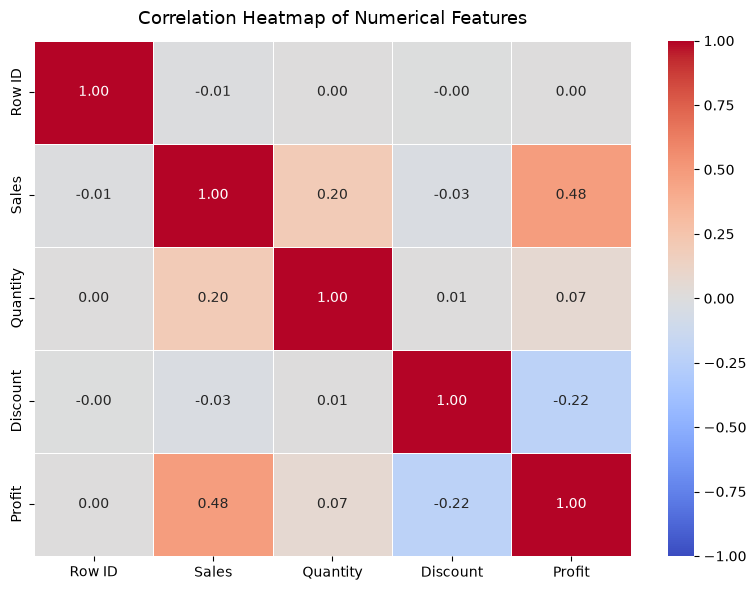

In [2]:
# ==============================================================================
# TASK 1: Load and Explore Data
# ==============================================================================
df = pd.read_csv("samplesuperstore.csv")

print("--- DATASET PREVIEW ---")
print(df.head())

print("\n--- DATASET INFO ---")
df.info()

print("\n--- NUMERICAL SUMMARY ---")
print(df.describe())

# Correlation heatmap
plt.figure(figsize=(8, 6))
numeric_cols_eda = df.select_dtypes(include=["number"])
sns.heatmap(
    numeric_cols_eda.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("Correlation Heatmap of Numerical Features", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

In [3]:
# ==============================================================================
# TASK 2: Clean Data & Feature Selection
# ==============================================================================
TARGET = "profit_class"
class_names = ["Loss", "Low margin", "High margin"]

# Engineer profit margin and target classes
margin = df["Profit"] / df["Sales"]
df[TARGET] = np.select([df["Profit"] < 0, margin < 0.25], [0, 1], default=2)

features = [
    "Ship Mode",
    "Segment",
    "Region",
    "Category",
    "Sub-Category",
    "Sales",
    "Quantity",
    "Discount",
]

df = df[features + [TARGET]].drop_duplicates().reset_index(drop=True)

print("\n--- TARGET CLASS DISTRIBUTION ---")
print(df[TARGET].value_counts().rename(index=dict(enumerate(class_names))))
print(f"Cleaned dataset shape: {df.shape}")


--- TARGET CLASS DISTRIBUTION ---
profit_class
High margin    5460
Low margin     2435
Loss           1862
Name: count, dtype: int64
Cleaned dataset shape: (9757, 9)


In [4]:
# ==============================================================================
# TASK 3: Preprocessing & Train-Test Split
# ==============================================================================
X = df.drop(columns=[TARGET])
y = df[TARGET]

categorical_cols = [
    "Ship Mode",
    "Segment",
    "Region",
    "Category",
    "Sub-Category",
]
numeric_cols = ["Sales", "Quantity", "Discount"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_cols,
        ),
        ("num", StandardScaler(), numeric_cols),
    ],
    remainder="drop",
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

In [5]:
# ==============================================================================
# TASK 4: Train Ensemble Models & Stacking
# ==============================================================================
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=12, random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, max_depth=12, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, max_depth=5, learning_rate=0.05, random_state=42
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150, max_depth=6, learning_rate=0.05, random_state=42
    ),
}

print("\n=== INDIVIDUAL MODEL PERFORMANCE (Macro F1) ===")
for name, model in models.items():
    model.fit(X_train_proc, y_train)
    preds = model.predict(X_test_proc)
    score = f1_score(y_test, preds, average="macro")
    print(f"{name:25s} | Macro F1: {score:.4f}")

# Train Stacking Classifier
meta_learner = LogisticRegression(max_iter=1000, random_state=42)

stacking_clf = StackingClassifier(
    estimators=list(models.items()),
    final_estimator=meta_learner,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    stack_method="predict_proba",
    n_jobs=-1,
)

print("\nFitting Stacking Classifier...")
stacking_clf.fit(X_train_proc, y_train)
stack_preds = stacking_clf.predict(X_test_proc)

print(
    f"{'Stacking':25s} | Macro F1: {f1_score(y_test, stack_preds, average='macro'):.4f}"
)

# Final Evaluation
print("\n" + "=" * 60)
print("FINAL STACKING CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, stack_preds, target_names=class_names))


=== INDIVIDUAL MODEL PERFORMANCE (Macro F1) ===
Random Forest             | Macro F1: 0.8111
Extra Trees               | Macro F1: 0.7957
Gradient Boosting         | Macro F1: 0.8269
Hist Gradient Boosting    | Macro F1: 0.8329

Fitting Stacking Classifier...
Stacking                  | Macro F1: 0.8288

FINAL STACKING CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Loss       0.92      0.82      0.87       373
  Low margin       0.70      0.72      0.71       487
 High margin       0.90      0.92      0.91      1092

    accuracy                           0.85      1952
   macro avg       0.84      0.82      0.83      1952
weighted avg       0.85      0.85      0.85      1952



In [6]:
# ==============================================================================
# TASK 5: Evaluate Models
# ==============================================================================
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Dictionary to hold predictions for all models (including Stacking)
all_models = {**models, "Stacking": stacking_clf}

# ---------------------------------------------------------
# 1. Generate Comparison Table
# ---------------------------------------------------------
comparison_records = []

for name, model in all_models.items():
    preds = np.ravel(model.predict(X_test_proc))

    acc = accuracy_score(y_test, preds)
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_test, preds, average="macro", zero_division=0
    )
    prec_weight, rec_weight, f1_weight, _ = precision_recall_fscore_support(
        y_test, preds, average="weighted", zero_division=0
    )

    comparison_records.append(
        {
            "Model": name,
            "Accuracy": acc,
            "Macro Precision": prec_macro,
            "Macro Recall": rec_macro,
            "Macro F1": f1_macro,
            "Weighted F1": f1_weight,
        }
    )

comparison_df = (
    pd.DataFrame(comparison_records)
    .sort_values(by="Macro F1", ascending=False)
    .reset_index(drop=True)
)

print("=" * 80)
print("MODEL COMPARISON TABLE (Ranked by Macro F1)")
print("=" * 80)
display(comparison_df.style.format({col: "{:.4f}" for col in comparison_df.columns if col != "Model"}))

# ---------------------------------------------------------
# 2. Detailed Classification Reports
# ---------------------------------------------------------
print("\n" + "=" * 80)
print("DETAILED CLASSIFICATION REPORTS PER MODEL")
print("=" * 80)

for name, model in all_models.items():
    preds = np.ravel(model.predict(X_test_proc))
    print(f"\n>>> Model: {name}")
    print(
        classification_report(
            y_test,
            preds,
            target_names=class_names,
            digits=4,
            zero_division=0,
        )
    )
    print("-" * 60)

MODEL COMPARISON TABLE (Ranked by Macro F1)


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Hist Gradient Boosting,0.8550,0.8441,0.8246,0.8329,0.8559
1,Stacking,0.8519,0.8392,0.8204,0.8288,0.8523
2,Gradient Boosting,0.8499,0.8386,0.8178,0.8269,0.8504
3,Random Forest,0.8371,0.8290,0.7982,0.8111,0.8373
4,Extra Trees,0.8263,0.8148,0.7809,0.7957,0.8245



DETAILED CLASSIFICATION REPORTS PER MODEL

>>> Model: Random Forest
              precision    recall  f1-score   support

        Loss     0.9327    0.7802    0.8496       373
  Low margin     0.6680    0.6940    0.6808       487
 High margin     0.8862    0.9203    0.9030      1092

    accuracy                         0.8371      1952
   macro avg     0.8290    0.7982    0.8111      1952
weighted avg     0.8407    0.8371    0.8373      1952

------------------------------------------------------------

>>> Model: Extra Trees
              precision    recall  f1-score   support

        Loss     0.9148    0.7775    0.8406       373
  Low margin     0.6603    0.6386    0.6493       487
 High margin     0.8694    0.9267    0.8972      1092

    accuracy                         0.8263      1952
   macro avg     0.8148    0.7809    0.7957      1952
weighted avg     0.8259    0.8263    0.8245      1952

------------------------------------------------------------

>>> Model: Gradient Bo

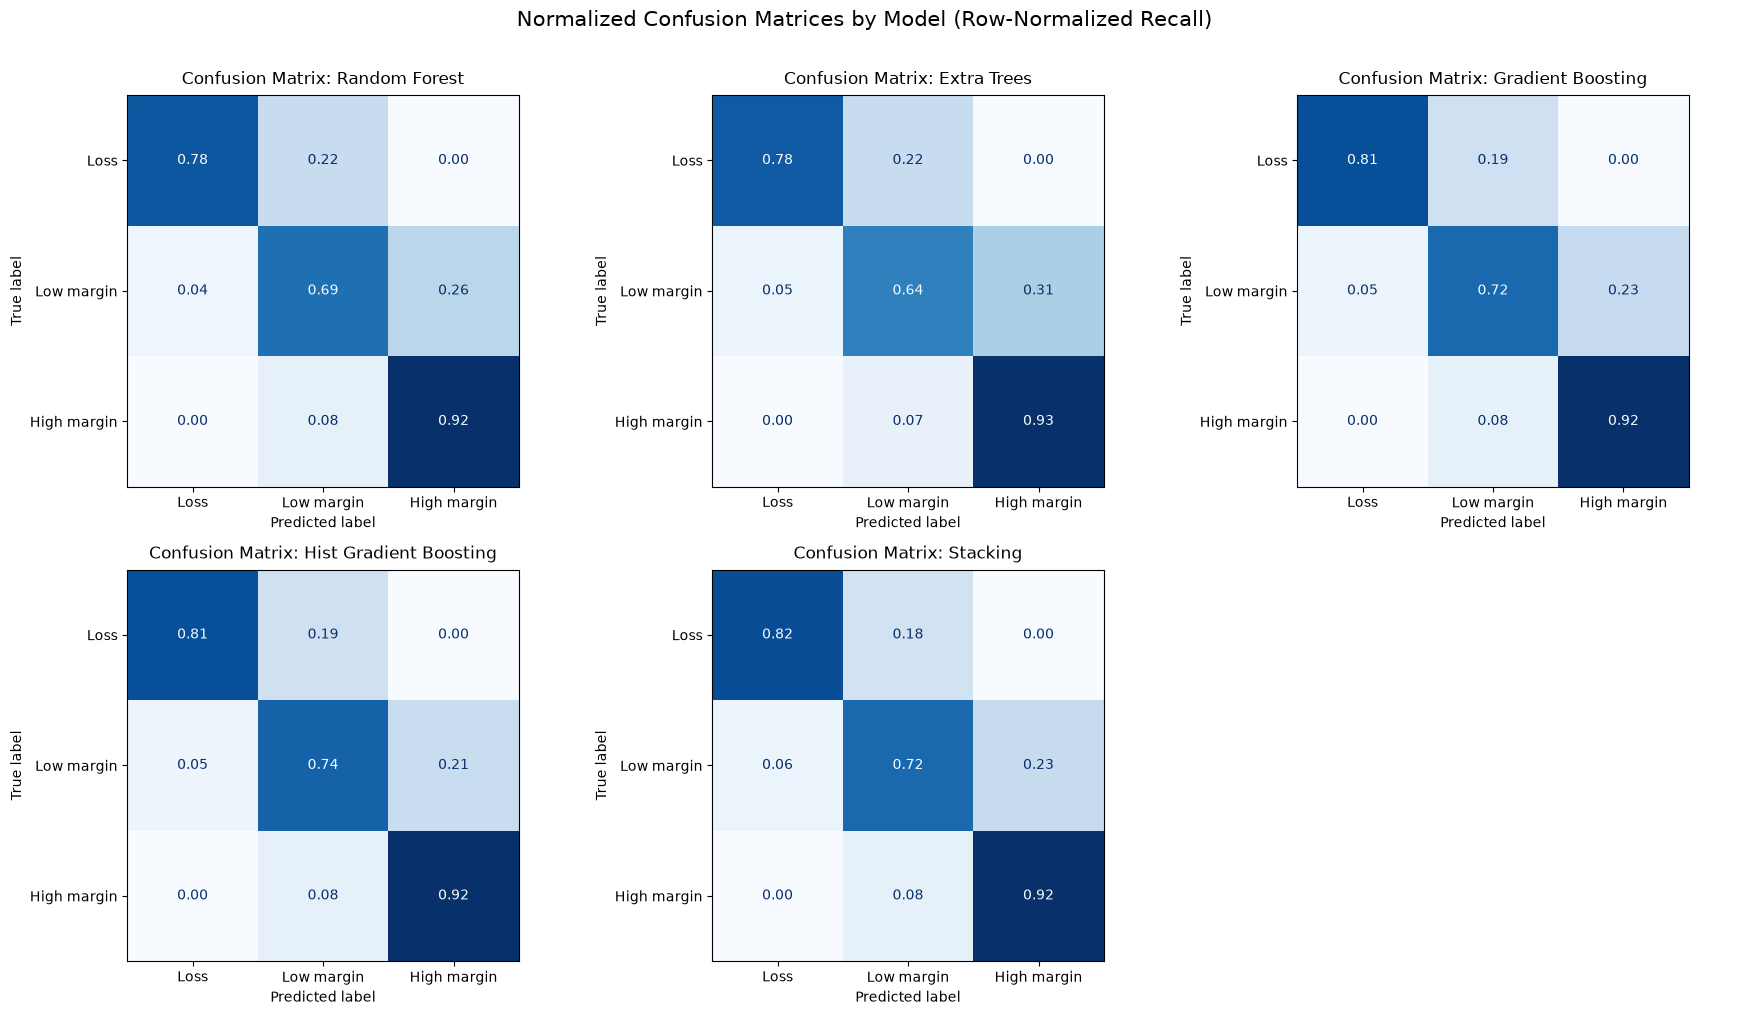

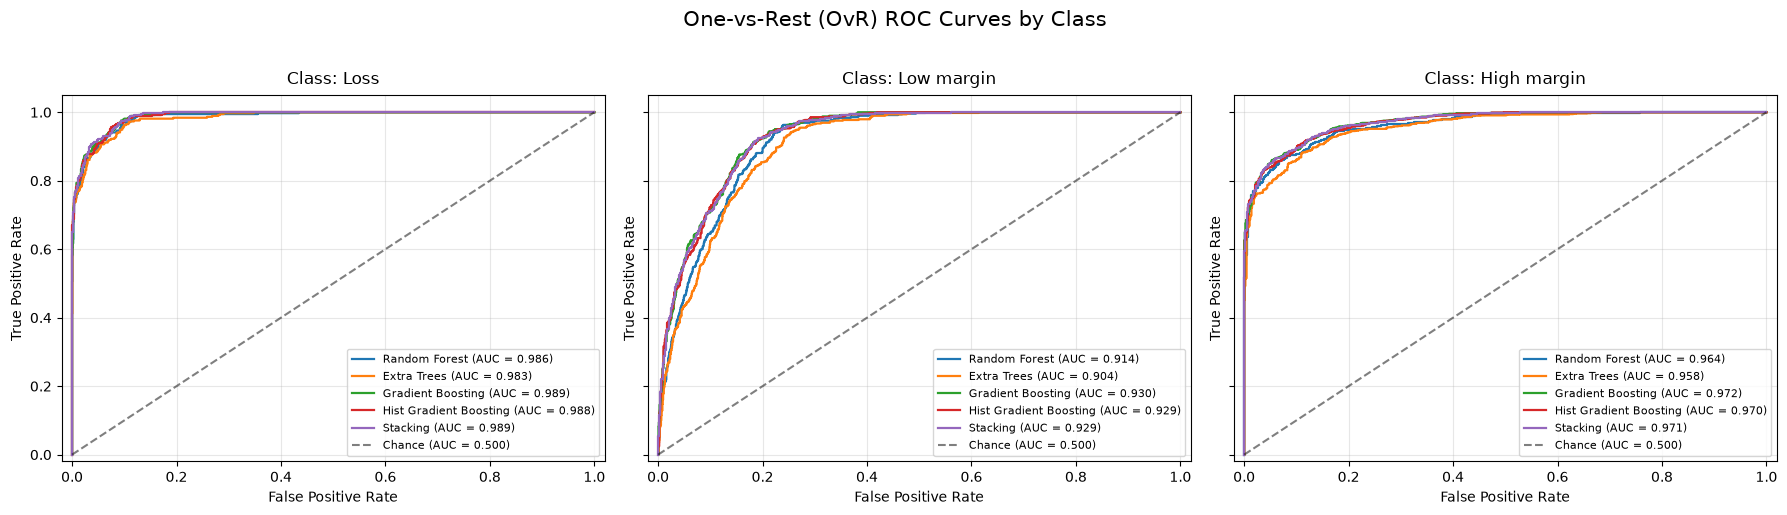

OVERALL MACRO ROC-AUC (One-vs-Rest)


,Model,Macro ROC-AUC
0,Gradient Boosting,0.9635
1,Stacking,0.9630
2,Hist Gradient Boosting,0.9625
3,Random Forest,0.9545
4,Extra Trees,0.9485


In [7]:

# ==============================================================================
# TASK 6: Visualize Model Performance
# ==============================================================================
import math
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, roc_curve
from sklearn.preprocessing import label_binarize

# ---------------------------------------------------------
# 1. Normalized Confusion Matrices (Grid layout)
# ---------------------------------------------------------
n_models = len(all_models)
ncols = 3
nrows = math.ceil(n_models / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows))
axes = np.array(axes).flatten()

for idx, (name, model) in enumerate(all_models.items()):
    preds = np.ravel(model.predict(X_test_proc))
    ConfusionMatrixDisplay.from_predictions(
        y_true=y_test,
        y_pred=preds,
        display_labels=class_names,
        normalize="true",  # shows recall proportions per true class
        cmap="Blues",
        values_format=".2f",
        ax=axes[idx],
        colorbar=False,
    )
    axes[idx].set_title(f"Confusion Matrix: {name}", fontsize=12, pad=8)
    axes[idx].grid(False)

# Hide any empty subplots in the grid
for ax in axes[n_models:]:
    ax.axis("off")

plt.suptitle(
    "Normalized Confusion Matrices by Model (Row-Normalized Recall)",
    fontsize=15,
    y=1.01,
)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. Multi-Class ROC Curves & One-vs-Rest (OvR) AUC
# ---------------------------------------------------------
# Binarize test ground truth into shape (n_samples, 3) for One-vs-Rest
n_classes = len(class_names)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

# Plotting setup: 1 subplot per profit class
fig, axes = plt.subplots(1, n_classes, figsize=(6 * n_classes, 5), sharey=True)

# Store macro ROC-AUC scores for summary comparison
macro_auc_scores = {}

for name, model in all_models.items():
    # Retrieve predicted probabilities (n_samples, 3)
    probs = model.predict_proba(X_test_proc)

    # Compute overall One-vs-Rest macro AUC
    macro_auc = roc_auc_score(
        y_test_bin, probs, multi_class="ovr", average="macro"
    )
    macro_auc_scores[name] = macro_auc

    # Plot ROC curve for each class slice
    for class_idx in range(n_classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, class_idx], probs[:, class_idx])
        class_auc = roc_auc_score(y_test_bin[:, class_idx], probs[:, class_idx])

        axes[class_idx].plot(
            fpr,
            tpr,
            label=f"{name} (AUC = {class_auc:.3f})",
            linewidth=1.6,
        )

# Format each class's ROC subplot
for class_idx in range(n_classes):
    ax = axes[class_idx]
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Chance (AUC = 0.500)")
    ax.set_title(f"Class: {class_names[class_idx]}", fontsize=12, pad=8)
    ax.set_xlabel("False Positive Rate", fontsize=10)
    ax.set_ylabel("True Positive Rate", fontsize=10)
    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.05])
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right", fontsize=8)

plt.suptitle("One-vs-Rest (OvR) ROC Curves by Class", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. Macro ROC-AUC Summary Table
# ---------------------------------------------------------
auc_df = (
    pd.DataFrame(list(macro_auc_scores.items()), columns=["Model", "Macro ROC-AUC"])
    .sort_values(by="Macro ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

print("=" * 45)
print("OVERALL MACRO ROC-AUC (One-vs-Rest)")
print("=" * 45)
display(auc_df.style.format({"Macro ROC-AUC": "{:.4f}"}))